In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# Notebook 03: Optimizer Comparison

## Campus Road Damage Detection and Severity-Aware Maintenance Prioritization

### Objective
Train the YOLOv8n model using the AdamW optimizer and compare
its performance with the SGD baseline model.

### Experiment Configuration
- Model: YOLOv8n
- Dataset: RDD2022 Preprocessed
- Optimizers: SGD and AdamW
- Completed Epochs: 16 per optimizer
- Image Size: 640 × 640
- Batch Size: 32
- GPU: Tesla T4 x2
- Evaluation Metrics: Precision, Recall, mAP50, mAP50-95

## Step 1: Project Setup and Imports

In [1]:
# ==========================================
# NOTEBOOK 03 - CELL 1
# Project Setup and Imports
# ==========================================

import os
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Dataset path
DATASET_PATH = Path(
    "/kaggle/input/datasets/ammritkumaar/rdd2022-preprocessed-yolo"
)

# Working directory
WORK_DIR = Path("/kaggle/working")

# Training output directory
PROJECT_DIR = WORK_DIR / "YOLO_Experiments"

PROJECT_DIR.mkdir(parents=True, exist_ok=True)

print("========== PROJECT SETUP ==========")

print("Dataset path:", DATASET_PATH)
print("Dataset exists:", DATASET_PATH.exists())

print("\nWorking directory:", WORK_DIR)
print("Project directory:", PROJECT_DIR)

print("\n========== GPU CHECK ==========")

print("CUDA Available:", torch.cuda.is_available())
print("GPU Count:", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

print("\n========== SETUP COMPLETED ==========")

========== PROJECT SETUP ==========
Dataset path: /kaggle/input/datasets/ammritkumaar/rdd2022-preprocessed-yolo
Dataset exists: True

Working directory: /kaggle/working
Project directory: /kaggle/working/YOLO_Experiments

========== GPU CHECK ==========
CUDA Available: True
GPU Count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4

========== SETUP COMPLETED ==========


## Step 2: Verify Prepared Dataset

Verify the training, validation, and test dataset
structure to ensure the same dataset is used for
both SGD and AdamW optimizer experiments.

In [2]:
# ==========================================
# NOTEBOOK 03 - CELL 2
# Verify Prepared Dataset
# ==========================================

from pathlib import Path

print("========== DATASET VERIFICATION ==========")

# Expected dataset counts
expected_counts = {
    "train": 16636,
    "val": 4753,
    "test": 2377
}

image_extensions = {".jpg", ".jpeg", ".png"}

for split in ["train", "val", "test"]:

    images_dir = DATASET_PATH / "images" / split
    labels_dir = DATASET_PATH / "labels" / split

    assert images_dir.exists(), f"Missing: {images_dir}"
    assert labels_dir.exists(), f"Missing: {labels_dir}"

    # Count images and labels
    images = [
        f for f in images_dir.iterdir()
        if f.suffix.lower() in image_extensions
    ]

    labels = list(labels_dir.glob("*.txt"))

    # Verify matching image-label names
    image_names = {f.stem for f in images}
    label_names = {f.stem for f in labels}

    missing_labels = image_names - label_names
    missing_images = label_names - image_names

    print(f"\n========== {split.upper()} ==========")
    print("Images:", len(images))
    print("Labels:", len(labels))
    print("Images without labels:", len(missing_labels))
    print("Labels without images:", len(missing_images))

    assert len(images) == expected_counts[split]
    assert len(labels) == expected_counts[split]
    assert not missing_labels
    assert not missing_images

print("\n========== DATASET VERIFIED ==========")
print("Same dataset as SGD baseline: Confirmed")
print("Total images: 23,766")

========== DATASET VERIFICATION ==========

========== TRAIN ==========
Images: 16636
Labels: 16636
Images without labels: 0
Labels without images: 0

========== VAL ==========
Images: 4753
Labels: 4753
Images without labels: 0
Labels without images: 0

========== TEST ==========
Images: 2377
Labels: 2377
Images without labels: 0
Labels without images: 0

========== DATASET VERIFIED ==========
Same dataset as SGD baseline: Confirmed
Total images: 23,766


## Step 3: Configure Dataset YAML

Create a dataset configuration file with Kaggle-specific
paths and the four road damage classes.

The same dataset configuration used for the SGD baseline
will be used for the AdamW optimizer experiment.

In [3]:
# ==========================================
# NOTEBOOK 03 - CELL 3
# Configure Dataset YAML
# ==========================================

import yaml
from pathlib import Path

# Create dataset configuration
data_config = {
    "path": str(DATASET_PATH),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": 4,
    "names": {
        0: "Longitudinal Crack",
        1: "Transverse Crack",
        2: "Alligator Crack",
        3: "Pothole"
    }
}

# Save YAML in Kaggle working directory
YAML_PATH = WORK_DIR / "data.yaml"

with open(YAML_PATH, "w") as f:
    yaml.safe_dump(data_config, f, sort_keys=False)

print("========== DATA YAML CONFIGURATION ==========")

print("\nYAML saved at:", YAML_PATH)
print("YAML exists:", YAML_PATH.exists())

print("\n--- YAML CONTENT ---")

with open(YAML_PATH, "r") as f:
    print(f.read())

print("========== CONFIGURATION COMPLETED ==========")

========== DATA YAML CONFIGURATION ==========

YAML saved at: /kaggle/working/data.yaml
YAML exists: True

--- YAML CONTENT ---
path: /kaggle/input/datasets/ammritkumaar/rdd2022-preprocessed-yolo
train: images/train
val: images/val
test: images/test
nc: 4
names:
  0: Longitudinal Crack
  1: Transverse Crack
  2: Alligator Crack
  3: Pothole

========== CONFIGURATION COMPLETED ==========


## Step 4: Install Ultralytics and Verify GPU

Install the same Ultralytics version used in the SGD
baseline experiment and verify the GPU environment
before training YOLOv8n using AdamW.

In [4]:
# ==========================================
# NOTEBOOK 03 - CELL 4
# Install Ultralytics and Verify GPU
# ==========================================

!pip install -q ultralytics==8.4.211

import ultralytics
import torch
from ultralytics import YOLO
from pathlib import Path

print("========== ENVIRONMENT CHECK ==========")

# 1. Check library versions
print("PyTorch version:", torch.__version__)
print("Ultralytics version:", ultralytics.__version__)

# 2. Verify GPU availability
print("\nCUDA Available:", torch.cuda.is_available())
print("GPU Count:", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):
    gpu = torch.cuda.get_device_properties(i)

    print(f"\nGPU {i}: {gpu.name}")
    print(
        "GPU Memory:",
        round(gpu.total_memory / (1024 ** 3), 2),
        "GB"
    )

# 3. Verify dataset YAML
print("\nYAML Path:", YAML_PATH)
print("YAML Exists:", Path(YAML_PATH).exists())

# 4. Final checks
assert torch.cuda.is_available(), "GPU not available!"
assert torch.cuda.device_count() == 2, "Enable T4 x2!"
assert Path(YAML_PATH).exists(), "Run Cell 3 first!"
assert ultralytics.__version__ == "8.4.211"

print("\n========== ENVIRONMENT READY ==========")
print("Ready for AdamW training!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
========== ENVIRONMENT CHECK ==========
PyTorch version: 2.11.0+cu130
Ultralytics version: 8.4.211

CUDA Available: True
GPU Count: 2

GPU 0: Tesla T4
GPU Memory: 14.56 GB

GPU 1: Tesla T4
GPU Memory: 14.56 GB

YAML Path: /kaggle/working/data.yaml
YAML Exists: True

========== ENVIRONMENT READY ==========
Ready for AdamW training!


## Step 5: Train YOLOv8n Using AdamW Optimizer

Train a fresh pretrained YOLOv8n model using the AdamW
optimizer on the RDD2022 preprocessed dataset.

### Training Configuration

- Model: YOLOv8n (pretrained)
- Optimizer: AdamW
- Planned Epochs: 50
- Comparison Checkpoint: 16 completed epochs
- Image Size: 640 × 640
- Batch Size: 32
- Initial Learning Rate: 0.001
- Weight Decay: 0.0005
- Random Seed: 42
- GPU: Tesla T4 x2
- Mixed Precision: Enabled

### Objective

Compare the AdamW training configuration with the SGD
baseline using Precision, Recall, mAP50 and mAP50-95
after 16 completed epochs.

In [5]:
# ==========================================
# NOTEBOOK 03 - CELL 5
# Train YOLOv8n with AdamW Optimizer
# ==========================================

from ultralytics import YOLO
from pathlib import Path
import torch
import time

# Dataset configuration
YAML_PATH = "/kaggle/working/data.yaml"

# Training output directory
PROJECT_DIR = "/kaggle/working/YOLO_Experiments"

# Verify environment
assert Path(YAML_PATH).exists()
assert torch.cuda.device_count() == 2

# Load fresh pretrained YOLOv8n model
model = YOLO("yolov8n.pt")

print("========== ADAMW TRAINING STARTED ==========")

start_time = time.time()

# Train model
results = model.train(

    # Dataset and training configuration
    data=YAML_PATH,
    epochs=50,
    imgsz=640,
    batch=32,

    # Use both Tesla T4 GPUs
    device=[0, 1],

    # AdamW optimizer configuration
    optimizer="AdamW",
    lr0=0.001,
    momentum=0.937,
    weight_decay=0.0005,
    cos_lr=True,

    # Reproducibility
    mosaic=0.0,
    seed=42,

    # Performance configuration
    workers=2,
    cache=False,
    amp=True,

    # Early stopping and checkpoints
    patience=15,
    save=True,
    save_period=5,
    plots=True,

    # Output configuration
    project=PROJECT_DIR,
    name="optimizer_yolov8n_adamw",
    exist_ok=False,
    verbose=True
)

# Calculate training time
elapsed = (time.time() - start_time) / 60

print("\n========== TRAINING COMPLETED ==========")

print("Training time:", round(elapsed, 2), "minutes")
print("Results directory:", model.trainer.save_dir)
print("Best model:", model.trainer.best)
print("Last model:", model.trainer.last)

========== ADAMW TRAINING STARTED ==========
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train,

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/50      2.62G      2.138      2.569       1.91         28        640: 100% ━━━━━━━━━━━━ 520/520 3.7it/s 2:220.2ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 75/75 2.4it/s 31.1s0.2ss
                   all       4752      11016      0.307      0.238      0.182     0.0723

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/50      2.62G      2.076      2.445      1.858         20        640: 100% ━━━━━━━━━━━━ 520/520 3.6it/s 2:230.2sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 75/75 2.3it/s 32.7s0.2ss
                   all       4752      11016      0.288      0.239      0.189     0.0761

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/50      2.62G      2.041       2.38      1.833         40      

W1113 09:34:53.075000 155 torch/distributed/elastic/agent/server/api.py:739] Received 2 death signal, shutting down workers
W1113 09:34:53.079000 155 torch/distributed/elastic/multiprocessing/api.py:1012] Sending process 158 closing signal SIGINT
W1113 09:34:53.082000 155 torch/distributed/elastic/multiprocessing/api.py:1012] Sending process 159 closing signal SIGINT
[rank1]: Traceback (most recent call last):
[rank1]:   File "/root/.config/Ultralytics/DDP/_temp_rsqd0t2k133550116886512.py", line 16, in <module>
[rank1]:     trainer.train()
[rank1]:     ~~~~~~~~~~~~~^^
[rank1]:   File "/usr/local/lib/python3.13/dist-packages/ultralytics/engine/trainer.py", line 264, in train
[rank1]:     self._do_train()
[rank1]:     ~~~~~~~~~~~~~~^^
[rank1]:   File "/usr/local/lib/python3.13/dist-packages/ultralytics/engine/trainer.py", line 522, in _do_train
[rank1]:     for i, batch in pbar:
[rank1]:                     ^^^^
[rank1]:   File "/usr/local/lib/python3.13/dist-packages/ultralytics/data/bu

KeyboardInterrupt: 

## Step 6: Verify Saved Training Results and Checkpoints

Verify the saved AdamW model weights, training history,
and completed epochs before comparing the performance
with the SGD baseline.

In [6]:
# ==========================================
# NOTEBOOK 03 - CELL 6
# Verify Saved Training Results
# ==========================================

from pathlib import Path
import pandas as pd

# Actual AdamW training directory
RUN_DIR = Path(
    "/kaggle/working/YOLO_Experiments/optimizer_yolov8n_adamw"
)

WEIGHTS_DIR = RUN_DIR / "weights"
RESULTS_CSV = RUN_DIR / "results.csv"

print("========== ADAMW RESULTS VERIFICATION ==========")

print("\nRun directory:", RUN_DIR)
print("Run directory exists:", RUN_DIR.exists())

# Check important files
print("\n========== SAVED FILES ==========")

important_files = [
    WEIGHTS_DIR / "best.pt",
    WEIGHTS_DIR / "last.pt",
    WEIGHTS_DIR / "epoch15.pt",
    RESULTS_CSV,
    RUN_DIR / "args.yaml"
]

for file in important_files:
    if file.exists():
        size_mb = file.stat().st_size / (1024 ** 2)
        print(f"{file.name}: EXISTS | {size_mb:.2f} MB")
    else:
        print(f"{file.name}: NOT FOUND")

# Verify training history
assert RESULTS_CSV.exists(), "results.csv not found!"

df_adamw = pd.read_csv(RESULTS_CSV)
df_adamw.columns = df_adamw.columns.str.strip()

print("\n========== TRAINING HISTORY ==========")

print("Completed epochs:", len(df_adamw))

print("\nLast 5 epochs:")
display(df_adamw.tail())

# Extract exact epoch 16 results
epoch16 = df_adamw[df_adamw["epoch"] == 16]

assert not epoch16.empty, "Epoch 16 results not found!"

print("\n========== EPOCH 16 RESULTS ==========")

display(epoch16)

# Best epoch according to mAP50-95
best_row = df_adamw.loc[
    df_adamw["metrics/mAP50-95(B)"].idxmax()
]

print("\n========== BEST EPOCH ==========")

print("Best epoch:", int(best_row["epoch"]))
print("Best mAP50:", best_row["metrics/mAP50(B)"])
print("Best mAP50-95:", best_row["metrics/mAP50-95(B)"])

print("\n========== VERIFICATION COMPLETED ==========")

========== ADAMW RESULTS VERIFICATION ==========

Run directory: /kaggle/working/YOLO_Experiments/optimizer_yolov8n_adamw
Run directory exists: True

========== SAVED FILES ==========
best.pt: EXISTS | 30.32 MB
last.pt: EXISTS | 30.32 MB
epoch15.pt: EXISTS | 30.32 MB
results.csv: EXISTS | 0.00 MB
args.yaml: EXISTS | 0.00 MB

========== TRAINING HISTORY ==========
Completed epochs: 16

Last 5 epochs:


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
11,12,3216.51,1.84843,2.01199,1.66974,0.49380,0.40154,0.39115,0.17497,1.84947,1.95345,1.66384,0.000886,0.000886,0.000886
12,13,3390.46,1.83849,1.98749,1.65386,0.49763,0.39591,0.39307,0.18328,1.80977,1.93503,1.63598,0.000866,0.000866,0.000866
13,14,3565.01,1.82142,1.96748,1.64945,0.51082,0.41204,0.41724,0.19320,1.81616,1.91121,1.64748,0.000844,0.000844,0.000844
14,15,3740.11,1.80696,1.93655,1.63897,0.51874,0.41876,0.42331,0.19502,1.81087,1.87657,1.61723,0.000821,0.000821,0.000821
15,16,3916.00,1.80918,1.90911,1.62198,0.51716,0.44247,0.44259,0.20797,1.78155,1.82987,1.59913,0.000796,0.000796,0.000796



========== EPOCH 16 RESULTS ==========


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
15,16,3916.0,1.80918,1.90911,1.62198,0.51716,0.44247,0.44259,0.20797,1.78155,1.82987,1.59913,0.000796,0.000796,0.000796



========== BEST EPOCH ==========
Best epoch: 16
Best mAP50: 0.44259
Best mAP50-95: 0.20797

========== VERIFICATION COMPLETED ==========


## Step 7: Optimizer Performance Comparison

Compare the performance of SGD and AdamW optimizers
after 16 completed training epochs.

The comparison includes:

- Precision
- Recall
- mAP50
- mAP50-95
- Training and validation losses
- Performance improvement

The better-performing model will be selected for
further validation and final test evaluation.

========== OPTIMIZER COMPARISON ==========


,Optimizer,Epochs,Precision,Recall,mAP50,mAP50-95,Train Box Loss,Train CLS Loss,Train DFL Loss,Val Box Loss,Val CLS Loss,Val DFL Loss
0,SGD,16,0.51169,0.41295,0.41924,0.19242,1.85228,1.97263,1.67894,1.81063,1.86243,1.63545
1,AdamW,16,0.51716,0.44247,0.44259,0.20797,1.80918,1.90911,1.62198,1.78155,1.82987,1.59913



========== PERFORMANCE IMPROVEMENT ==========


,Metric,SGD (%),AdamW (%),Improvement (pp)
0,Precision,51.169,51.716,0.547
1,Recall,41.295,44.247,2.952
2,mAP50,41.924,44.259,2.335
3,mAP50-95,19.242,20.797,1.555


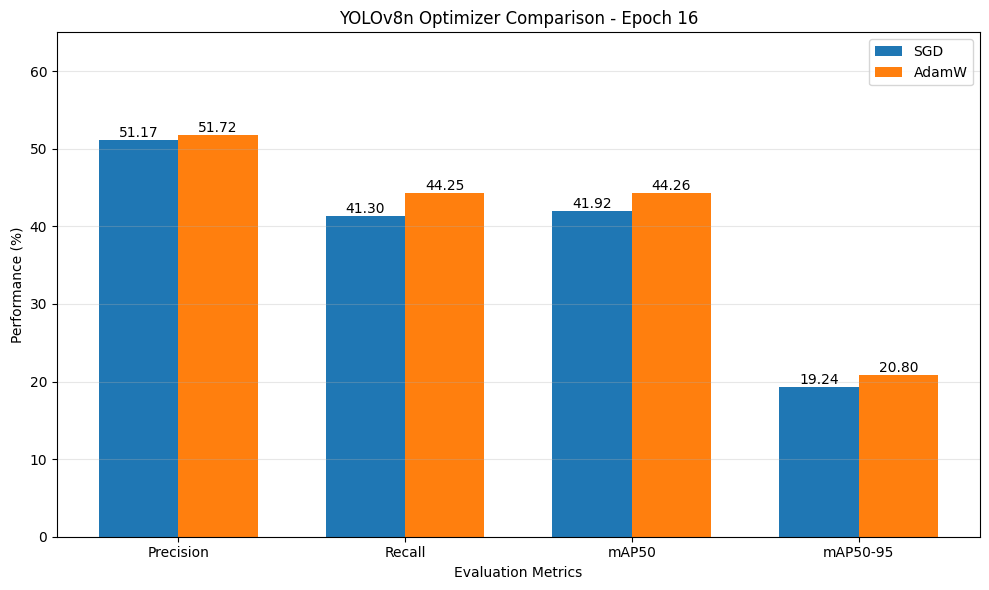

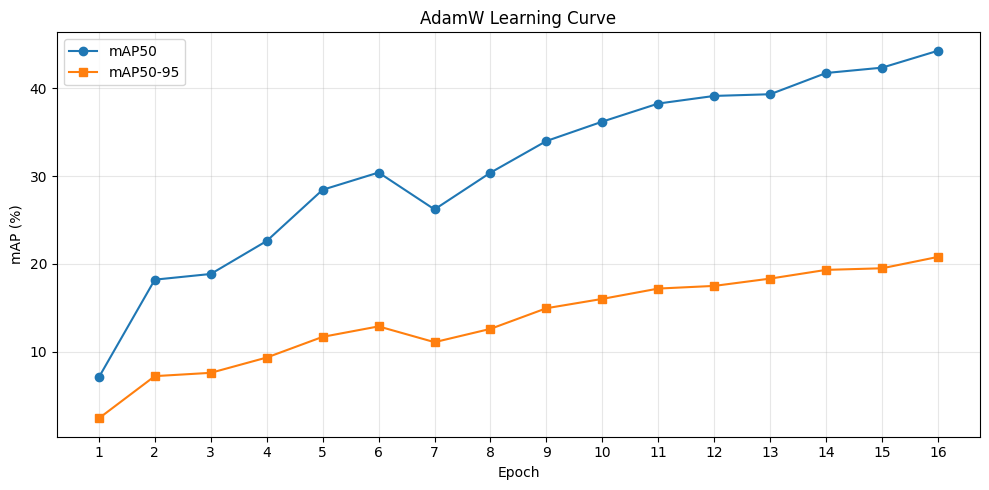


========== BEST OPTIMIZER ==========
Selected optimizer: AdamW
mAP50: 44.259 %
mAP50-95: 20.797 %

========== FILES SAVED ==========
performance_improvement.csv
adamw_learning_curve.png
optimizer_comparison.png
optimizer_comparison.csv

Comparison directory: /kaggle/working/Optimizer_Comparison

========== COMPARISON COMPLETED ==========


In [7]:
# ==========================================
# NOTEBOOK 03 - CELL 7
# Optimizer Performance Comparison
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Create comparison output directory
COMPARISON_DIR = Path(
    "/kaggle/working/Optimizer_Comparison"
)

COMPARISON_DIR.mkdir(parents=True, exist_ok=True)

# ==========================================
# 1. SGD baseline results (Epoch 16)
# ==========================================

sgd_results = {
    "Optimizer": "SGD",
    "Epochs": 16,
    "Precision": 0.51169,
    "Recall": 0.41295,
    "mAP50": 0.41924,
    "mAP50-95": 0.19242,
    "Train Box Loss": 1.85228,
    "Train CLS Loss": 1.97263,
    "Train DFL Loss": 1.67894,
    "Val Box Loss": 1.81063,
    "Val CLS Loss": 1.86243,
    "Val DFL Loss": 1.63545
}

# ==========================================
# 2. AdamW results from actual CSV
# ==========================================

adamw_epoch16 = df_adamw[
    df_adamw["epoch"] == 16
].iloc[0]

adamw_results = {
    "Optimizer": "AdamW",
    "Epochs": 16,
    "Precision": adamw_epoch16["metrics/precision(B)"],
    "Recall": adamw_epoch16["metrics/recall(B)"],
    "mAP50": adamw_epoch16["metrics/mAP50(B)"],
    "mAP50-95": adamw_epoch16["metrics/mAP50-95(B)"],
    "Train Box Loss": adamw_epoch16["train/box_loss"],
    "Train CLS Loss": adamw_epoch16["train/cls_loss"],
    "Train DFL Loss": adamw_epoch16["train/dfl_loss"],
    "Val Box Loss": adamw_epoch16["val/box_loss"],
    "Val CLS Loss": adamw_epoch16["val/cls_loss"],
    "Val DFL Loss": adamw_epoch16["val/dfl_loss"]
}

# ==========================================
# 3. Create comparison table
# ==========================================

comparison_df = pd.DataFrame([
    sgd_results,
    adamw_results
])

print("========== OPTIMIZER COMPARISON ==========")

display(comparison_df)

# Save comparison CSV
comparison_df.to_csv(
    COMPARISON_DIR / "optimizer_comparison.csv",
    index=False
)

# ==========================================
# 4. Calculate performance improvement
# ==========================================

metrics = [
    "Precision",
    "Recall",
    "mAP50",
    "mAP50-95"
]

improvement_data = []

for metric in metrics:

    sgd_value = sgd_results[metric]
    adamw_value = adamw_results[metric]

    improvement = (adamw_value - sgd_value) * 100

    improvement_data.append({
        "Metric": metric,
        "SGD (%)": sgd_value * 100,
        "AdamW (%)": adamw_value * 100,
        "Improvement (pp)": improvement
    })

improvement_df = pd.DataFrame(improvement_data)

print("\n========== PERFORMANCE IMPROVEMENT ==========")

display(improvement_df.round(3))

improvement_df.to_csv(
    COMPARISON_DIR / "performance_improvement.csv",
    index=False
)

# ==========================================
# 5. Performance comparison graph
# ==========================================

x = np.arange(len(metrics))
width = 0.35

sgd_values = [
    sgd_results[m] * 100 for m in metrics
]

adamw_values = [
    adamw_results[m] * 100 for m in metrics
]

fig, ax = plt.subplots(figsize=(10, 6))

bars1 = ax.bar(
    x - width / 2,
    sgd_values,
    width,
    label="SGD"
)

bars2 = ax.bar(
    x + width / 2,
    adamw_values,
    width,
    label="AdamW"
)

ax.set_title(
    "YOLOv8n Optimizer Comparison - Epoch 16"
)

ax.set_xlabel("Evaluation Metrics")
ax.set_ylabel("Performance (%)")

ax.set_xticks(x)
ax.set_xticklabels(metrics)

ax.set_ylim(0, 65)
ax.legend()
ax.grid(axis="y", alpha=0.3)

ax.bar_label(bars1, fmt="%.2f")
ax.bar_label(bars2, fmt="%.2f")

plt.tight_layout()

plt.savefig(
    COMPARISON_DIR / "optimizer_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ==========================================
# 6. AdamW learning curve
# ==========================================

adamw_history = df_adamw[
    df_adamw["epoch"] <= 16
]

plt.figure(figsize=(10, 5))

plt.plot(
    adamw_history["epoch"],
    adamw_history["metrics/mAP50(B)"] * 100,
    marker="o",
    label="mAP50"
)

plt.plot(
    adamw_history["epoch"],
    adamw_history["metrics/mAP50-95(B)"] * 100,
    marker="s",
    label="mAP50-95"
)

plt.title("AdamW Learning Curve")
plt.xlabel("Epoch")
plt.ylabel("mAP (%)")
plt.xticks(range(1, 17))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    COMPARISON_DIR / "adamw_learning_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ==========================================
# 7. Select better optimizer
# ==========================================

best_optimizer = comparison_df.loc[
    comparison_df["mAP50-95"].idxmax()
]

print("\n========== BEST OPTIMIZER ==========")

print("Selected optimizer:", best_optimizer["Optimizer"])
print("mAP50:", round(best_optimizer["mAP50"] * 100, 3), "%")
print(
    "mAP50-95:",
    round(best_optimizer["mAP50-95"] * 100, 3),
    "%"
)

print("\n========== FILES SAVED ==========")

for file in COMPARISON_DIR.iterdir():
    print(file.name)

print("\nComparison directory:", COMPARISON_DIR)

print("\n========== COMPARISON COMPLETED ==========")

## Step 8: Save and Backup Experiment Results

Create a ZIP backup containing the AdamW model weights,
training history, optimizer comparison results, and
performance visualization graphs.

The saved model will be used in subsequent validation,
final test evaluation, and severity-aware maintenance
prioritization notebooks.

In [8]:
# ==========================================
# NOTEBOOK 03 - CELL 8
# Save and Backup Experiment Results
# ==========================================

import shutil
from pathlib import Path

# Source directories
RUN_DIR = Path(
    "/kaggle/working/YOLO_Experiments/optimizer_yolov8n_adamw"
)

COMPARISON_DIR = Path(
    "/kaggle/working/Optimizer_Comparison"
)

# Backup directory
BACKUP_DIR = Path(
    "/kaggle/working/AdamW_Optimizer_Comparison_Backup"
)

BACKUP_DIR.mkdir(parents=True, exist_ok=True)

print("========== CREATING BACKUP ==========")

# Verify required files before backup
assert (RUN_DIR / "weights/best.pt").exists()
assert (RUN_DIR / "weights/last.pt").exists()
assert (RUN_DIR / "weights/epoch15.pt").exists()
assert (RUN_DIR / "results.csv").exists()
assert (COMPARISON_DIR / "optimizer_comparison.csv").exists()

# Copy AdamW training results
shutil.copytree(
    RUN_DIR,
    BACKUP_DIR / "AdamW_Training",
    dirs_exist_ok=True
)

print("AdamW training results copied!")

# Copy optimizer comparison results
shutil.copytree(
    COMPARISON_DIR,
    BACKUP_DIR / "Optimizer_Comparison",
    dirs_exist_ok=True
)

print("Optimizer comparison results copied!")

# Copy dataset configuration
shutil.copy2(
    "/kaggle/working/data.yaml",
    BACKUP_DIR / "data.yaml"
)

print("Dataset configuration copied!")

# Create ZIP archive
ZIP_PATH = shutil.make_archive(
    "/kaggle/working/AdamW_Optimizer_Comparison_16_Epochs",
    "zip",
    root_dir=BACKUP_DIR
)

# Verify ZIP file
zip_file = Path(ZIP_PATH)

assert zip_file.exists()

print("\n========== BACKUP COMPLETED ==========")

print("ZIP file:", ZIP_PATH)

print(
    "ZIP size:",
    round(zip_file.stat().st_size / (1024 ** 2), 2),
    "MB"
)

print("\n========== BACKUP CONTENTS ==========")

for file in sorted(BACKUP_DIR.rglob("*")):

    if file.is_file():

        print(file.relative_to(BACKUP_DIR))

print("\n========== ALL RESULTS SAVED ==========")

========== CREATING BACKUP ==========
AdamW training results copied!
Optimizer comparison results copied!
Dataset configuration copied!

========== BACKUP COMPLETED ==========
ZIP file: /kaggle/working/AdamW_Optimizer_Comparison_16_Epochs.zip
ZIP size: 169.48 MB

========== BACKUP CONTENTS ==========
AdamW_Training/args.yaml
AdamW_Training/labels.jpg
AdamW_Training/results.csv
AdamW_Training/train_batch0.jpg
AdamW_Training/train_batch1.jpg
AdamW_Training/train_batch2.jpg
AdamW_Training/weights/best.pt
AdamW_Training/weights/epoch0.pt
AdamW_Training/weights/epoch10.pt
AdamW_Training/weights/epoch15.pt
AdamW_Training/weights/epoch5.pt
AdamW_Training/weights/last.pt
Optimizer_Comparison/adamw_learning_curve.png
Optimizer_Comparison/optimizer_comparison.csv
Optimizer_Comparison/optimizer_comparison.png
Optimizer_Comparison/performance_improvement.csv
data.yaml

========== ALL RESULTS SAVED ==========


## Step 9: Download Experiment Backup

Download the complete AdamW optimizer experiment backup
for permanent storage and subsequent model evaluation.

In [9]:
# ==========================================
# NOTEBOOK 03 - CELL 9
# Download Experiment Backup
# ==========================================

import os
from IPython.display import FileLink, display

# Set working directory
os.chdir("/kaggle/working")

# Generate download link
display(
    FileLink(
        "AdamW_Optimizer_Comparison_16_Epochs.zip"
    )
)

/kaggle/working/AdamW_Optimizer_Comparison_16_Epochs.zip